In [ ]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import normaltest, probplot

warnings.filterwarnings("ignore")

In [4]:
from bank_churn_predictions.dataset import load_stage1_data

In [5]:
df = load_stage1_data()

2026-10-09 17:36:52.165 | INFO     | bank_churn_predictions.dataset:load_stage1_data:16 - Loading stage 1 dataset from D:\Ravindu\Programming\My Roadmap\Phase 1\bank_churn_predictions\data\interim\stage_1_preprocessing.csv
2026-10-09 17:36:52.200 | INFO     | bank_churn_predictions.dataset:load_stage1_data:20 - Loaded 10000 rows and 11 columns


## Scaling Continous Numeric Columns

In [6]:
numeric_cols = ["CreditScore", "Age", "Balance", "EstimatedSalary"]
# specifying all continous numerical columns to make it easier for future analysis

In [7]:
for x in numeric_cols:
    print(
        f"Column {x} has a minimum of {min(df[x])}, maximum of {max(df[x])}, a mean of {np.mean(df[x])} and a standard deviation of {np.std(df[x])}"
    )

Column CreditScore has a minimum of 350, maximum of 850, a mean of 650.5288 and a standard deviation of 96.64846595037089
Column Age has a minimum of 18, maximum of 92, a mean of 38.9218 and a standard deviation of 10.487282048271611
Column Balance has a minimum of 0.0, maximum of 250898.09, a mean of 76485.889288 and a standard deviation of 62394.285254125185
Column EstimatedSalary has a minimum of 11.58, maximum of 199992.48, a mean of 100090.239881 and a standard deviation of 57507.617221165565


<span>
<p>No null values, therefore no NA preprocessing needs to be done. However, as clearly seen most of the numerical columns have widely varying ranges of values</p>
<p>Therefore, they will need to be sufficiently scaled to prevent the model being influenced by imbalanced data. The method of scaling can be decided </p></span>

In [8]:
for x in numeric_cols:
    print(f"Is the data in column {x} normally distributed : {normaltest(df[x])[1] > 0.05}")

Is the data in column CreditScore normally distributed : False
Is the data in column Age normally distributed : False
Is the data in column Balance normally distributed : False
Is the data in column EstimatedSalary normally distributed : False


<p>As no data is normally distributed, scaling methods such as Standard Scaling seems unsuitable, for the standard p value of 0.05. However its important to keep in mind that these negatives could be attributed to a few large outliers skewing measures of normalcy, which is something that will need to be tested</p>

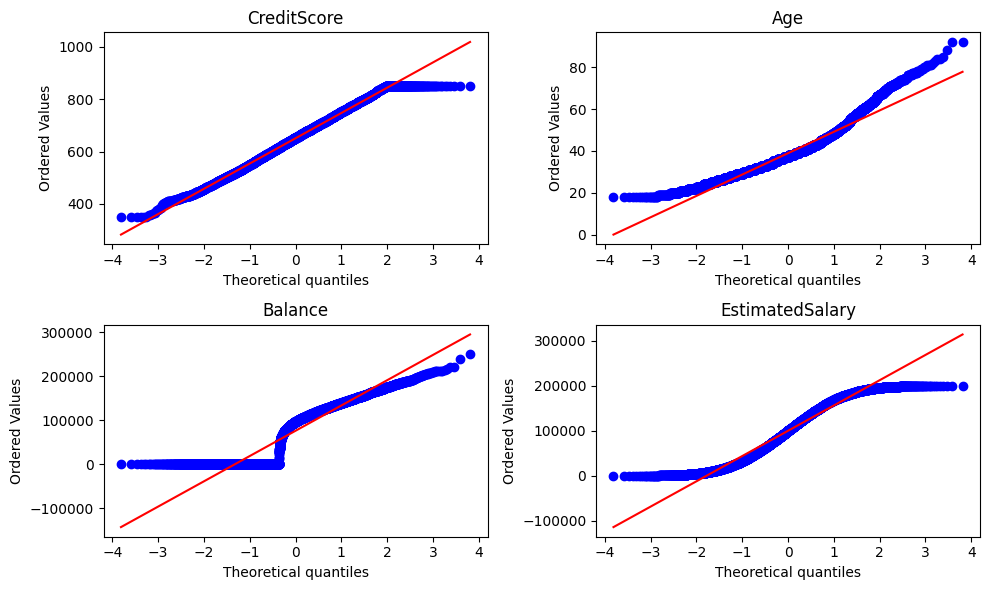

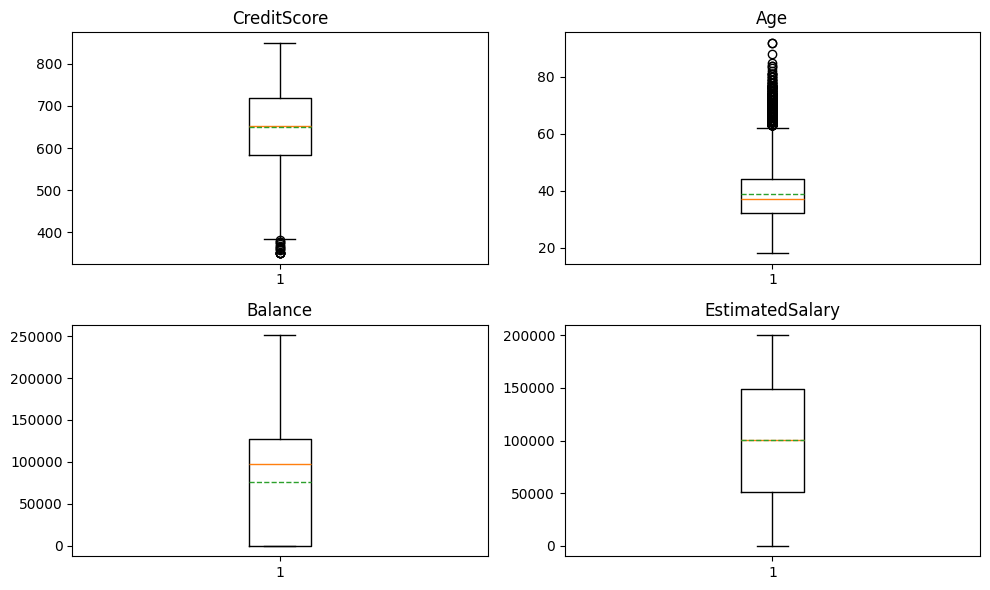

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
count = 0
for x in range(2):
    for y in range(2):
        probplot(df[numeric_cols[count]], dist="norm", plot=axes[x % 2, y])
        axes[x, y].set_title(numeric_cols[count])
        count += 1

plt.tight_layout()
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
count = 0
for x in range(2):
    for y in range(2):
        axes[x, y].boxplot(df[numeric_cols[count]], showmeans=True, meanline=True)
        axes[x, y].set_title(numeric_cols[count])
        count += 1

plt.tight_layout()

<p>This graph reveals some interesting things about our values. Values like Credit Score (represented by the red line) due to domain restrictions (for instance, credit score cannot increase above 850). Lets look at each variable individually</p>
<ul>
    <li><b>Credit Score</b>: As can be seen here, despite there being clustering at the ends (due to natural limits of 0 and 850), it is more or less perfectly in line with the line of normal distribution, making it suitable for standard scaling</li>
    <li><b>Age</b>: The data follows the line of standard distribution, yet there is clear deviation towards the upper end of the feature. This indicates a significant level of skewnss, which suggests that standard scaling should not be applied here as it is sensitive to outliers. This is further supported by the boxplot which clearly shows that Age has a significant amount of outliers towards the upper limit</li>
    <li><b>Balance</b>: The almost straight line between the theoretical quantile of -4 and 0 for the probability plot indicate that almost half of the dataset is heavily centered around the lower tail end of the data. This hypothesis is further supported uneveness indicated by the histogram attached below as well as the boxplot for this feature, which has no significant lower whisker, starkly contrasted to the extremely lengthy upper whisker, an sign of extreme feature uneveness. This is indicative of the fact that this dataset is unsuitable for standard scaling, due to it being heavily skewed; the extreme skew suggests that other forms of scaling, such as robust scaling, might have to be pursued </li>
    <li><b>Estimated Salary</b>: The boxplot for this shows that the data has achieved almost perfect even distribution, as the mean is approximately equal to the median, the whiskers are of approximate equal length, and the quartiles are evenly spaced (Q1 is ~50,000, Q2 is ~100,000 and Q3 is ~150,000, each having almost even spacing between each other). The clustering at the tail ends are to be expected; after all, salaries often do not go above or beyond a certain limit (for instance, having a salary of above 200,000 dollars per year may be uncommon amongst the general population). Barring that, the lack of outliers or extreme values makes this feature suitable for normal scaling</li>
</ul>

In [10]:
df.Exited.value_counts(normalize=True)

Exited
0    0.7963
1    0.2037
Name: proportion, dtype: float64

<p> I also need to handle this class imbalance. There's significantly more instances of '0' (didn't leave) than there are instances of '1' (left). I plan on using SMOTENC (not SMOTE itself as SMOTENC is more useful when there's a mix of discrete and continous features) to reduce the class imbalance, test the generated data and its usefulness with models later on, and if it doesn't work I can consider moving onto other techniques later on</p>

<p>Some additional things I want to do is a simple correlation analysis to understand feature relationships; right now its impossible to conduct as categorical data still has not been properly encoded, but this will continue in the next section</p>